# Video Converter: NPY to MP4

This notebook converts NumPy array video files (.npy format) to MP4 video files for use in the SLEAP post-processing pipeline.

## Overview:
1. **Load raw video data**: Read .npy files containing video frames
2. **Convert format**: Transform NumPy arrays to MP4 video format
3. **Organize output**: Copy converted videos to organized directory structure
4. **Prepare for SLEAP**: Set up directory structure for SLEAP analysis

## Configuration
**IMPORTANT**: Update the input and output paths below to match your data directory structure.

In [1]:
import os
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time
import h5py
from utilities.saving import create_folder
from utilities.reorganize_files import copy_file
from utilities.reading_movie_manage_batch import sorted_alphanumeric,read_mp4_video,process_batch
from utilities.reading_data_from_exp import h5tree_view, extract_time_from_date
from utilities.plotting_postprocessing import fig_traj_allRuns

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'    
%load_ext autoreload
%autoreload 2
warnings.filterwarnings("ignore")

# Configuration: Set Input and Output Paths

**IMPORTANT**: Configure the paths below to point to your data directories.

**Input**: Raw video data stored as .npy files (typically on external drives)
**Output**: Converted MP4 files organized in Desktop/postprocessed_[condition]/ structure

In [ ]:
# ============================================================================
# CONFIGURATION: Set input data path
# ============================================================================
# Update this path to point to your raw video data directory
# The path should contain experiment day folders (e.g., fs_12dpf_15Dec25)

# Option 1: Use one of the predefined paths (uncomment the one you need)
input_path = os.environ.get('RAW_DATA_DIR', r'/path/to/your/raw/data')

# Option 2: Use a custom path (uncomment and modify)

# Validate input path exists
if not os.path.exists(input_path):
    raise FileNotFoundError(f"Input path not found: {input_path}\n"
                           f"Please update the 'input_path' variable above to point to your data directory.")

print(f"Using input path: {input_path}")
print("\nAvailable experiment folders (sorted by modification time):")
files = [os.path.join(input_path, f) for f in os.listdir(input_path)]
files_sorted = sorted(files, key=os.path.getmtime, reverse=True)
for f in files_sorted:
    if not os.path.basename(f).startswith('.'):  # Skip hidden files
        print(f"  - {os.path.basename(f)}")

fs_12dpf_15Dec25
fs_32dpf_04Apr25
dark.png
README.txt
bg.bmp
stones_frame_gradient_110624.png
stones_gradient_060624.png
bg-grayscale.jpg


In [ ]:
# ============================================================================
# CONFIGURATION: Set experiment day folder
# ============================================================================
folder_name = 'fs_12dpf_15Dec25'  # Change this to your experiment day folder name

input_dir_experiment_day = os.path.join(input_path, folder_name)
print(f"Experiment day folder: {input_dir_experiment_day}")

if not os.path.exists(input_dir_experiment_day):
    available = [f for f in os.listdir(input_path) if not f.startswith('.')]
    raise FileNotFoundError(f'ERROR: Experiment folder does not exist: {input_dir_experiment_day}\n'
                           f'Available folders:\n  {chr(10).join(available)}')
else:
    print(f"✓ Experiment folder found")
    print("\nContents:")
    for file in os.listdir(input_dir_experiment_day):
        if not file.startswith('.'):  # Skip hidden files
            print(f"  - {file}")

<raw_data_dir>/fs_12dpf_15Dec25
bg_mean.npy
fish_1
fish_2
fish_3
fish_4
fish_5


In [ ]:
# ============================================================================
# CONFIGURATION: Set fish number
# ============================================================================
fish_number = '5'  # Change this to '1', '2', '3', '4', '5', etc.

In [98]:
input_dir_experiment_fish_aux = os.path.join(input_dir_experiment_day,'fish_'+ str(fish_number))
if not os.path.exists(os.path.join(input_path,input_dir_experiment_fish_aux)):
    print('ERROR: this folder does not exist.')
else:
    print('input_dir_experiment_fish_aux exists properly, path: ', input_dir_experiment_fish_aux)

input_dir_experiment_fish_aux exists properly, path:  <raw_data_dir>/fs_12dpf_15Dec25/fish_5


In [109]:
freely_swimming = False
if not freely_swimming:
    exp_step = 'dark'#'ablation'#'pre'
    input_dir_experiment_fish = os.path.join(input_dir_experiment_fish_aux,exp_step)
else:
    input_dir_experiment_fish = input_dir_experiment_fish_aux

# Set output path

In [110]:
# Proper absolute path to Desktop
desktop = os.path.join(os.path.expanduser("~"), "Desktop")
path_out = os.path.join(desktop, "postprocessed_dark")
#path_out = os.path.join(desktop, "postprocessed_fs")

output_dir_experiment_day = os.path.join(path_out,folder_name)
create_folder(output_dir_experiment_day)

output_dir_experiment_fish_aux = os.path.join(output_dir_experiment_day,'fish_'+ str(fish_number))
if not freely_swimming:
    output_dir_experiment_fish = os.path.join(output_dir_experiment_fish_aux,exp_step)
else:   
    output_dir_experiment_fish = output_dir_experiment_fish_aux
create_folder(output_dir_experiment_fish)


Error: Folder already exists at: <output_dir>/fs_12dpf_15Dec25
Folder created at: <output_dir>/fs_12dpf_15Dec25/fish_5/dark


In [111]:
create_folder(os.path.join(output_dir_experiment_fish,'converted_movie'))
create_folder(os.path.join(output_dir_experiment_fish,'experiment_runs'))
create_folder(os.path.join(output_dir_experiment_fish,'labels_sleap'))
create_folder(os.path.join(output_dir_experiment_fish,'postprocessed_runs'))
create_folder(os.path.join(output_dir_experiment_fish,'plots'))

path_converted_movie=os.path.join(output_dir_experiment_fish,'converted_movie')
path_experiment_runs=os.path.join(output_dir_experiment_fish,'experiment_runs')
path_labels_sleap=os.path.join(output_dir_experiment_fish,'labels_sleap')
path_postprocessed_runs=os.path.join(output_dir_experiment_fish,'postprocessed_runs')
path_plots=os.path.join(output_dir_experiment_fish,'plots')

Folder created at: <output_dir>/fs_12dpf_15Dec25/fish_5/dark/converted_movie
Folder created at: <output_dir>/fs_12dpf_15Dec25/fish_5/dark/experiment_runs
Folder created at: <output_dir>/fs_12dpf_15Dec25/fish_5/dark/labels_sleap
Folder created at: <output_dir>/fs_12dpf_15Dec25/fish_5/dark/postprocessed_runs
Folder created at: <output_dir>/fs_12dpf_15Dec25/fish_5/dark/plots


# Move run*.h5 in path_experiment_runs

In [112]:
# Count total runs
n_run_tot = sum(1 for file in os.listdir(input_dir_experiment_fish) if file.startswith("run"))

# Copy each run's .h5 file
for i in range(n_run_tot):
    run_folder = f"run{i+1}"
    h5_experiment_run = os.path.join(input_dir_experiment_fish, run_folder, run_folder + '.h5')

    if os.path.isfile(h5_experiment_run):
        copy_file(h5_experiment_run, path_experiment_runs)
    else:
        print(f"⚠️ File not found: {h5_experiment_run}")

✅ File copied from <raw_data_dir>/fs_12dpf_15Dec25/fish_5/dark/run1/run1.h5 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/experiment_runs
✅ File copied from <raw_data_dir>/fs_12dpf_15Dec25/fish_5/dark/run2/run2.h5 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/experiment_runs


In [113]:
from utilities.reorganize_files import copy_file

n_run_tot=0
for file in os.listdir(input_dir_experiment_fish):
    if file[0:3]=='run':
        n_run_tot=n_run_tot+1
        
for i in range(n_run_tot):
    h5_experiment_run=os.path.join(input_dir_experiment_fish,'run'+str(i+1),'run'+str(i+1)+'.h5')
    copy_file(h5_experiment_run, path_experiment_runs)

✅ File copied from <raw_data_dir>/fs_12dpf_15Dec25/fish_5/dark/run1/run1.h5 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/experiment_runs
✅ File copied from <raw_data_dir>/fs_12dpf_15Dec25/fish_5/dark/run2/run2.h5 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/experiment_runs


# Save traj in plots

In [114]:
tot_traj=[[] for i in range(n_run_tot)]
time_traj=[[] for i in range(n_run_tot)]
category_names=[[] for i in range(n_run_tot)]
date_f_run=[[] for i in range(n_run_tot)]
date_i_run=[[] for i in range(n_run_tot)]
date_in_arena=[[] for i in range(n_run_tot)]

#from natsort import natsorted

#for i, file in enumerate(natsorted(os.listdir(path_experiment_runs))):
#    print(f'{i}: {file}') 
for i,file in enumerate(os.listdir(path_experiment_runs)):
    print(f'{i}:, {file}')
    h5_experiment_run=os.path.join(path_experiment_runs,file)
    hdf5_file = h5py.File(h5_experiment_run, "r") 
    #h5tree_view(hdf5_file)
    tot_traj[i]=hdf5_file['data/motorpositions'][:]
    date_f_run[i]=hdf5_file['data/date_f_run'][:]
    date_i_run[i]=hdf5_file['data/date_i_run'][:]
    fr_camera=hdf5_file['data/cameratimes'][:] 
    aux=hdf5_file['data/motortimes'][:]  
    time_traj[i]=round((aux[-1]-aux[0])/60,2)
    category_names[i]='run'+str(i+1)

0:, run1.h5
1:, run2.h5


In [115]:
fps=int(1/np.mean(np.diff(fr_camera)))
print(f'fps recording {fps}')

fps recording 249


In [116]:
time_runs = [ extract_time_from_date(date_i_run[i][0]) for i in range(n_run_tot)]
time_runs

['18:07:15', '18:10:17']

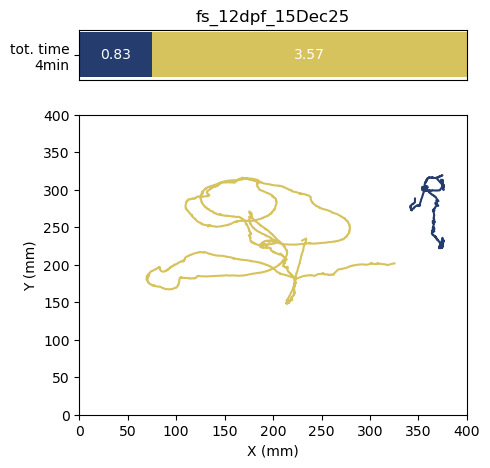

In [117]:
duration_runs = {'tot. time\n'+str(round(np.sum(time_traj)))+'min': time_traj}

title=title=folder_name
[fig,ax,category_colors]=fig_traj_allRuns(duration_runs,time_runs,category_names,title)
#ax[1].imshow(new_im_array[:,::-1],origin='lower',alpha=0.3,extent=[x_center_motor-im_pos[0]-im_size[0]/2,x_center_motor-im_pos[0]+im_size[0]/2,y_center_motor-im_pos[1]-im_size[1]/2,y_center_motor-im_pos[1]+im_size[1]/2])
for i in range(n_run_tot):
    ax[1].plot(tot_traj[i][:,0],tot_traj[i][:,1],c=category_colors[i],alpha=1)
    ax[1].set_xlabel('X (mm)')
    ax[1].set_ylabel('Y (mm)')
    #ax[1].axis('equal')
    ax[1].set_xlim([0,400])
    ax[1].set_ylim([0,400])
plt.savefig(os.path.join(path_plots,title+".pdf"), dpi=150)
plt.savefig(os.path.join(path_plots,title+".jpg"), dpi=150)
plt.show()

# Start converting video in .mp4

In [118]:
import os
import shutil
import re

for file in os.listdir(input_dir_experiment_fish):
    if file.startswith('run'):
        print('=' * 50)
        print(f"Start processing .mp4 videos of {file}")

        dir_experiment_run = os.path.join(input_dir_experiment_fish, file)
        path_movie = os.path.join(dir_experiment_run, 'movie')
        id_run = file

        all_files = os.listdir(path_movie)

        # Only select movie_<number>.mp4 files
        pattern = re.compile(r'^movie_(\d+)\.mp4$')
        matched_files = sorted(
            [f for f in all_files if pattern.match(f)],
            key=lambda x: int(pattern.match(x).group(1))
        )

        if not matched_files:
            print(f"No .mp4 files found in {path_movie}")
            continue

        for i, f in enumerate(matched_files):
            src = os.path.join(path_movie, f)
            dst = os.path.join(path_converted_movie, f'converted_{id_run}_movie{i}.mp4')
            shutil.copy(src, dst)
            print(f'✔ copied {f} to {dst}')

        print(f'✔ All .mp4 files copied for {id_run}')
        print('=' * 50)

Start processing .mp4 videos of run1
✔ copied movie_0.mp4 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/converted_movie/converted_run1_movie0.mp4
✔ All .mp4 files copied for run1
Start processing .mp4 videos of run2
✔ copied movie_0.mp4 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/converted_movie/converted_run2_movie0.mp4
✔ copied movie_1.mp4 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/converted_movie/converted_run2_movie1.mp4
✔ copied movie_2.mp4 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/converted_movie/converted_run2_movie2.mp4
✔ copied movie_3.mp4 to <output_dir>/fs_12dpf_15Dec25/fish_5/dark/converted_movie/converted_run2_movie3.mp4
✔ All .mp4 files copied for run2
